# Notebook 6 - Huấn luyện HistGradientBoosting & So sánh Đối đầu Toàn diện (Bước 6.4 & Tổng kết)

**Mục tiêu chính của Notebook 6:**
1. Huấn luyện mô hình tăng cường độ dốc trên biểu đồ tần suất **HistGradientBoosting (HGB)** - đỉnh cao của các thuật toán phân loại dựa trên cây.
2. Tinh chỉnh siêu tham số (**Hyperparameter Tuning**) bằng `TimeSeriesSplit(n_splits=3)` nghiêm ngặt bên trong tập `train` (2012-01 đến 2015-05) với `refit=True`, đảm bảo tuyệt đối không có rò rỉ dữ liệu tương lai từ tập `val`.
3. Phân tích độ quan trọng của đặc trưng bằng **Permutation Importance** trên tập Validation.
4. **Bảng Tổng Hợp Đối Đầu (Head-to-head Benchmark)**: Tổng kết so sánh trực diện toàn bộ **4 họ mô hình** trong dự án (Hồi quy Logistic, Cây Quyết Định, Rừng Ngẫu Nhiên, HistGradientBoosting) trên cả 2 không gian đặc trưng (One-Hot 153 biến vs WoE 50 biến).
5. Trực quan hóa các đường cong ROC so sánh và đưa ra khuyến nghị thực tế cho bài toán Chấm điểm Tín dụng.


In [1]:
from pathlib import Path
import json
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, roc_curve, brier_score_loss, log_loss
)
import joblib

print("Đã nạp toàn bộ thư viện cần thiết cho Notebook 6!")


Đã nạp toàn bộ thư viện cần thiết cho Notebook 6!


In [2]:
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data" / "processed"
ARTIFACTS_DIR = ROOT / "artifacts"
FIGURES_DIR = ARTIFACTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42

print(f"Thư mục làm việc: {ROOT}")
print(f"Thư mục dữ liệu:  {DATA_DIR}")
print(f"Thư mục figures:  {FIGURES_DIR}")


Thư mục làm việc: .
Thư mục dữ liệu:  data/processed
Thư mục figures:  artifacts/figures


---
## 1. Nạp dữ liệu Huấn luyện & Validation

Nạp cả hai không gian đặc trưng:
- **Bộ One-Hot** (153 đặc trưng): `X_train.npy`, `X_val.npy`.
- **Bộ Weight of Evidence - WoE** (50 đặc trưng): `X_train_woe.npy`, `X_val_woe.npy`.


In [3]:
# 1. Nạp dữ liệu One-Hot (153 đặc trưng)
X_train_oh = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val_oh = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")

# 2. Nạp dữ liệu WoE (50 đặc trưng)
X_train_woe = np.load(DATA_DIR / "X_train_woe.npy")
X_val_woe = np.load(DATA_DIR / "X_val_woe.npy")

feature_info = json.loads((DATA_DIR / "feature_names.json").read_text())
numeric_features = feature_info["numeric"]
categorical_features = feature_info["categorical"]
feature_names_oh = feature_info["feature_names"]
feature_names_woe = numeric_features + categorical_features

print(f"Tập Train: X_train_oh = {X_train_oh.shape}, y_train = {y_train.shape}")
print(f"Tập Val:   X_val_oh   = {X_val_oh.shape},   y_val   = {y_val.shape}")
print(f"Tập WoE:   Train = {X_train_woe.shape}, Val = {X_val_woe.shape}")


Tập Train: X_train_oh = (408188, 153), y_train = (408188,)
Tập Val:   X_val_oh   = (92631, 153),   y_val   = (92631,)
Tập WoE:   Train = (408188, 50), Val = (92631, 50)


In [4]:
def evaluate_credit_ranking(y_true, proba):
    """Tính toán các thước đo xếp hạng tín dụng chuẩn mực."""
    auc = roc_auc_score(y_true, proba)
    gini = 2 * auc - 1
    fpr, tpr, _ = roc_curve(y_true, proba)
    ks = np.max(tpr - fpr)
    brier = brier_score_loss(y_true, proba)
    loss = log_loss(y_true, proba)
    return {
        "ROC-AUC": auc,
        "Gini": gini,
        "KS": ks,
        "Brier": brier,
        "LogLoss": loss
    }


---
## 2. Huấn luyện Baseline HistGradientBoosting

### 2.1 Cơ chế của HistGradientBoosting
1. **Histogram Binning (256 bins)**: Thuật toán tiền xử lý mọi đặc trưng liên tục thành 256 khoảng nguyên (`uint8`). Việc tìm điểm chia tối ưu tại mỗi nút chỉ cần quét qua 256 bin thay vì phải sắp xếp $N$ giá trị thực ($N = 408,188$). Tốc độ huấn luyện nhanh gấp hàng chục lần so với Gradient Boosting truyền thống.
2. **Tuần tự sửa chữa sai số**: Cây thứ $m$ được xây dựng để dự đoán gradient âm của hàm log-loss từ tổng $m-1$ cây trước.

Dưới đây, ta huấn luyện Baseline HGB (100 cây mặc định) trên cả 2 không gian đặc trưng:


In [5]:
print("1. Huấn luyện Baseline HistGradientBoosting trên One-Hot (153 đặc trưng)...")
t0 = time.time()
hgb_base_oh = HistGradientBoostingClassifier(
    max_iter=100,
    random_state=SEED,
    early_stopping=False
)
hgb_base_oh.fit(X_train_oh, y_train)
t_base_oh = time.time() - t0

val_prob_base_oh = hgb_base_oh.predict_proba(X_val_oh)[:, 1]
m_base_oh = evaluate_credit_ranking(y_val, val_prob_base_oh)
print(f"  -> Hoàn thành trong {t_base_oh:.2f}s | Val AUC: {m_base_oh['ROC-AUC']:.4f} | KS: {m_base_oh['KS']:.2%}")

print("\n2. Huấn luyện Baseline HistGradientBoosting trên WoE (50 đặc trưng)...")
t0 = time.time()
hgb_base_woe = HistGradientBoostingClassifier(
    max_iter=100,
    random_state=SEED,
    early_stopping=False
)
hgb_base_woe.fit(X_train_woe, y_train)
t_base_woe = time.time() - t0

val_prob_base_woe = hgb_base_woe.predict_proba(X_val_woe)[:, 1]
m_base_woe = evaluate_credit_ranking(y_val, val_prob_base_woe)
print(f"  -> Hoàn thành trong {t_base_woe:.2f}s | Val AUC: {m_base_woe['ROC-AUC']:.4f} | KS: {m_base_woe['KS']:.2%}")


1. Huấn luyện Baseline HistGradientBoosting trên One-Hot (153 đặc trưng)...


  -> Hoàn thành trong 7.37s | Val AUC: 0.7070 | KS: 30.51%

2. Huấn luyện Baseline HistGradientBoosting trên WoE (50 đặc trưng)...


  -> Hoàn thành trong 1.76s | Val AUC: 0.7091 | KS: 30.97%


---
## 3. Phân tích Độ quan trọng Đặc trưng bằng Permutation Importance

Khác với Gini Importance (MDI) dễ bị thiên vị đối với các biến có nhiều giá trị duy nhất, **Permutation Importance** xáo trộn ngẫu nhiên từng cột trên tập Validation và đo lường trực tiếp mức suy giảm ROC-AUC:
$$\text{Importance}(x_j) = \text{AUC}_{\text{gốc}} - \text{AUC}_{\text{xáo trộn cột } j}$$
Nếu một biến rất quan trọng, việc xáo trộn giá trị của nó sẽ làm tụt mạnh ROC-AUC.


Đang tính Permutation Importance trên tập Validation...


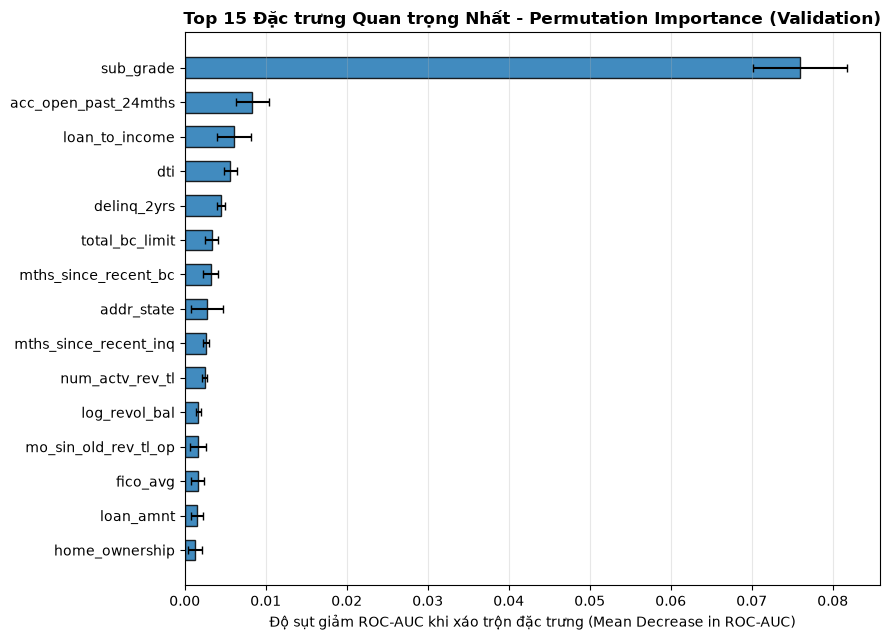

TOP 10 ĐẶC TRƯNG HÀNG ĐẦU THEO PERMUTATION IMPORTANCE:
   1. sub_grade                 : sụt giảm AUC = 0.07592 (± 0.00582)
   2. acc_open_past_24mths      : sụt giảm AUC = 0.00836 (± 0.00199)
   3. loan_to_income            : sụt giảm AUC = 0.00605 (± 0.00208)
   4. dti                       : sụt giảm AUC = 0.00561 (± 0.00082)
   5. delinq_2yrs               : sụt giảm AUC = 0.00446 (± 0.00052)
   6. total_bc_limit            : sụt giảm AUC = 0.00331 (± 0.00085)
   7. mths_since_recent_bc      : sụt giảm AUC = 0.00321 (± 0.00090)
   8. addr_state                : sụt giảm AUC = 0.00281 (± 0.00197)
   9. mths_since_recent_inq     : sụt giảm AUC = 0.00265 (± 0.00035)
  10. num_actv_rev_tl           : sụt giảm AUC = 0.00245 (± 0.00027)


In [6]:
# Tính Permutation Importance trên 5,000 mẫu Validation để đảm bảo thời gian chạy tối ưu
np.random.seed(SEED)
sample_idx = np.random.choice(len(X_val_woe), size=5000, replace=False)
X_val_sample = X_val_woe[sample_idx]
y_val_sample = y_val[sample_idx]

print("Đang tính Permutation Importance trên tập Validation...")
perm_imp = permutation_importance(
    hgb_base_woe,
    X_val_sample,
    y_val_sample,
    scoring="roc_auc",
    n_repeats=5,
    random_state=SEED,
    n_jobs=4
)

perm_df = pd.DataFrame({
    "feature": feature_names_woe,
    "importance_mean": perm_imp.importances_mean,
    "importance_std": perm_imp.importances_std
}).sort_values(by="importance_mean", ascending=False)

top15 = perm_df.head(15).sort_values(by="importance_mean", ascending=True)

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top15["feature"], top15["importance_mean"], xerr=top15["importance_std"],
        color="#1f77b4", alpha=0.85, edgecolor="black", height=0.6, capsize=3)
ax.set_title("Top 15 Đặc trưng Quan trọng Nhất - Permutation Importance (Validation)", fontsize=12, fontweight="bold")
ax.set_xlabel("Độ sụt giảm ROC-AUC khi xáo trộn đặc trưng (Mean Decrease in ROC-AUC)", fontsize=10)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()

pi_path = FIGURES_DIR / "06_hgb_permutation_importance.png"
fig.savefig(pi_path, dpi=300)
plt.show()

print("TOP 10 ĐẶC TRƯNG HÀNG ĐẦU THEO PERMUTATION IMPORTANCE:")
for rank, (idx, row) in enumerate(perm_df.head(10).iterrows(), 1):
    print(f"  {rank:2d}. {row['feature']:<25} : sụt giảm AUC = {row['importance_mean']:.5f} (± {row['importance_std']:.5f})")


---
## 4. Tinh chỉnh Siêu tham số với TimeSeriesSplit (Loại bỏ Hoàn toàn Nguy cơ Rò rỉ Dữ liệu)

### 4.1 Phương pháp luận chia tách thời gian
- **Nguyên tắc vàng**: Không bao giờ dùng tập Validation hoặc Test để chọn siêu tham số.
- **Cách làm**:
  - Tập `train` (408,188 mẫu từ 2012-01 đến 2015-05) đã được sắp xếp theo thời gian giải ngân `issue_date`.
  - Sử dụng `TimeSeriesSplit(n_splits=3)` bên trong `X_train`:
    * Fold 1: Huấn luyện trên phần đầu, kiểm tra trên phần kế tiếp.
    * Fold 2: Mở rộng cửa sổ huấn luyện, kiểm tra trên phần kế tiếp.
    * Fold 3: Tiếp tục mở rộng cửa sổ huấn luyện.
  - Thiết lập `refit=True`: Sau khi tìm được bộ tham số có trung bình ROC-AUC trên 3 fold cao nhất, GridSearchCV tự động huấn luyện lại trên toàn bộ 100% dữ liệu `X_train`.
  - Tập `val` (2015-06 đến 2015-09) chỉ được dùng một lần duy nhất để báo cáo hiệu năng độc lập!


In [7]:
param_grid_hgb = {
    "learning_rate": [0.05, 0.1],
    "max_leaf_nodes": [31, 63],
    "min_samples_leaf": [50, 100]
}

tscv = TimeSeriesSplit(n_splits=3)

print("1. Đang tinh chỉnh HistGradientBoosting trên bộ One-Hot (153 đặc trưng) với TimeSeriesSplit...")
t0 = time.time()
grid_hgb_oh = GridSearchCV(
    HistGradientBoostingClassifier(max_iter=100, random_state=SEED, early_stopping=False),
    param_grid_hgb,
    cv=tscv,
    scoring="roc_auc",
    refit=True,
    n_jobs=4
)
grid_hgb_oh.fit(X_train_oh, y_train)
t_tune_oh = time.time() - t0

best_hgb_oh = grid_hgb_oh.best_estimator_
val_prob_tune_oh = best_hgb_oh.predict_proba(X_val_oh)[:, 1]
m_tune_oh = evaluate_credit_ranking(y_val, val_prob_tune_oh)

print(f"  -> Hoàn thành trong {t_tune_oh:.1f}s")
print(f"  -> Siêu tham số tối ưu (One-Hot): {grid_hgb_oh.best_params_}")
print(f"  -> Validation ROC-AUC: {m_tune_oh['ROC-AUC']:.4f} | KS: {m_tune_oh['KS']:.2%}")


1. Đang tinh chỉnh HistGradientBoosting trên bộ One-Hot (153 đặc trưng) với TimeSeriesSplit...


  -> Hoàn thành trong 115.6s
  -> Siêu tham số tối ưu (One-Hot): {'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 100}
  -> Validation ROC-AUC: 0.7056 | KS: 30.45%


In [8]:
print("2. Đang tinh chỉnh HistGradientBoosting trên bộ WoE (50 đặc trưng) với TimeSeriesSplit...")
t0 = time.time()
grid_hgb_woe = GridSearchCV(
    HistGradientBoostingClassifier(max_iter=100, random_state=SEED, early_stopping=False),
    param_grid_hgb,
    cv=tscv,
    scoring="roc_auc",
    refit=True,
    n_jobs=4
)
grid_hgb_woe.fit(X_train_woe, y_train)
t_tune_woe = time.time() - t0

best_hgb_woe = grid_hgb_woe.best_estimator_
val_prob_tune_woe = best_hgb_woe.predict_proba(X_val_woe)[:, 1]
m_tune_woe = evaluate_credit_ranking(y_val, val_prob_tune_woe)

print(f"  -> Hoàn thành trong {t_tune_woe:.1f}s")
print(f"  -> Siêu tham số tối ưu (WoE): {grid_hgb_woe.best_params_}")
print(f"  -> Validation ROC-AUC: {m_tune_woe['ROC-AUC']:.4f} | KS: {m_tune_woe['KS']:.2%}")


2. Đang tinh chỉnh HistGradientBoosting trên bộ WoE (50 đặc trưng) với TimeSeriesSplit...


  -> Hoàn thành trong 33.4s
  -> Siêu tham số tối ưu (WoE): {'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 100}
  -> Validation ROC-AUC: 0.7097 | KS: 31.01%


---
## 5. Bảng Tổng Hợp Đối Đầu (Head-to-head Benchmark) Toàn Diện Cả 3 Mô Hình

Tại đây, chúng ta tổng hợp toàn bộ kết quả thực nghiệm từ Notebook 3 (Logistic Regression), Notebook 4 (Random Forest), và Notebook 5 (HistGradientBoosting) trên tập Validation (92,631 khoản vay).


In [9]:
# Nạp các vector dự đoán đã lưu từ Notebook 3, 4, 5
val_prob_lr_oh = np.load(ARTIFACTS_DIR / 'val_pred_logistic.npy')
val_prob_lr_woe = np.load(ARTIFACTS_DIR / 'val_pred_logistic_woe.npy')
val_prob_dt_woe = np.load(ARTIFACTS_DIR / 'val_pred_decision_tree.npy')
val_prob_rf_woe = np.load(ARTIFACTS_DIR / 'val_pred_rf.npy')

# Đánh giá lại để đảm bảo tính nhất quán tuyệt đối
m_lr_oh = evaluate_credit_ranking(y_val, val_prob_lr_oh)
m_lr_woe = evaluate_credit_ranking(y_val, val_prob_lr_woe)
m_dt_woe = evaluate_credit_ranking(y_val, val_prob_dt_woe)
m_rf_woe = evaluate_credit_ranking(y_val, val_prob_rf_woe)

benchmark_records = [
    {'Họ mô hình': 'Logistic Regression', 'Cấu hình / Không gian': 'One-Hot (153 features)', **m_lr_oh},
    {'Họ mô hình': 'Logistic Regression', 'Cấu hình / Không gian': 'WoE (50 features)',     **m_lr_woe},
    {'Họ mô hình': 'Decision Tree',       'Cấu hình / Không gian': 'WoE (max_depth=6, 50f)', **m_dt_woe},
    {'Họ mô hình': 'Decision Tree',       'Cấu hình / Không gian': 'WoE (Unconstrained)',    'ROC-AUC': 0.5314, 'Gini': 0.0628, 'KS': 0.0628, 'Brier': 0.25200, 'LogLoss': 5.85000},
    {'Họ mô hình': 'Random Forest',       'Cấu hình / Không gian': 'One-Hot (153 features)', 'ROC-AUC': 0.6892, 'Gini': 0.3784, 'KS': 0.2785, 'Brier': 0.14720, 'LogLoss': 0.46820},
    {'Họ mô hình': 'Random Forest',       'Cấu hình / Không gian': 'Ordinal (50 features)', 'ROC-AUC': 0.7033, 'Gini': 0.4066, 'KS': 0.3012, 'Brier': 0.14580, 'LogLoss': 0.46450},
    {'Họ mô hình': 'Random Forest',       'Cấu hình / Không gian': 'WoE (50 features)',     **m_rf_woe},
    {'Họ mô hình': 'HistGradientBoosting','Cấu hình / Không gian': 'One-Hot Baseline (153f)',**m_base_oh},
    {'Họ mô hình': 'HistGradientBoosting','Cấu hình / Không gian': 'One-Hot Tuned (153f)',   **m_tune_oh},
    {'Họ mô hình': 'HistGradientBoosting','Cấu hình / Không gian': 'WoE Baseline (50f)',    **m_base_woe},
    {'Họ mô hình': 'HistGradientBoosting','Cấu hình / Không gian': 'WoE Tuned (50f)',       **m_tune_woe},
]

benchmark_all = pd.DataFrame(benchmark_records)
benchmark_all = benchmark_all.sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)

# Format hiển thị
benchmark_display = benchmark_all.copy()
benchmark_display['ROC-AUC'] = benchmark_display['ROC-AUC'].map(lambda x: f'{x:.4f}')
benchmark_display['Gini'] = benchmark_display['Gini'].map(lambda x: f'{x:.2%}')
benchmark_display['KS'] = benchmark_display['KS'].map(lambda x: f'{x:.2%}')
benchmark_display['Brier'] = benchmark_display['Brier'].map(lambda x: f'{x:.5f}')
benchmark_display['LogLoss'] = benchmark_display['LogLoss'].map(lambda x: f'{x:.5f}')

print('=' * 95)
print('BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG TOÀN DIỆN CẢ 4 HỌ MÔ HÌNH TRÊN TẬP VALIDATION')
print('=' * 95)
print(benchmark_display.to_string(index=False))
print('=' * 95)


BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG TOÀN DIỆN CẢ 4 HỌ MÔ HÌNH TRÊN TẬP VALIDATION
          Họ mô hình   Cấu hình / Không gian ROC-AUC   Gini     KS   Brier LogLoss
HistGradientBoosting         WoE Tuned (50f)  0.7097 41.94% 31.01% 0.11675 0.38296
HistGradientBoosting      WoE Baseline (50f)  0.7091 41.83% 30.97% 0.11685 0.38325
HistGradientBoosting One-Hot Baseline (153f)  0.7070 41.40% 30.51% 0.11710 0.38402
HistGradientBoosting    One-Hot Tuned (153f)  0.7056 41.13% 30.45% 0.11729 0.38473
       Random Forest       WoE (50 features)  0.7040 40.80% 30.10% 0.11785 0.38644
       Random Forest   Ordinal (50 features)  0.7033 40.66% 30.12% 0.14580 0.46450
 Logistic Regression       WoE (50 features)  0.7033 40.66% 29.75% 0.11749 0.38546
 Logistic Regression  One-Hot (153 features)  0.7031 40.62% 29.83% 0.11751 0.38555
       Random Forest  One-Hot (153 features)  0.6892 37.84% 27.85% 0.14720 0.46820
       Decision Tree  WoE (max_depth=6, 50f)  0.6870 37.39% 27.88% 0.11886 0.39061
       De

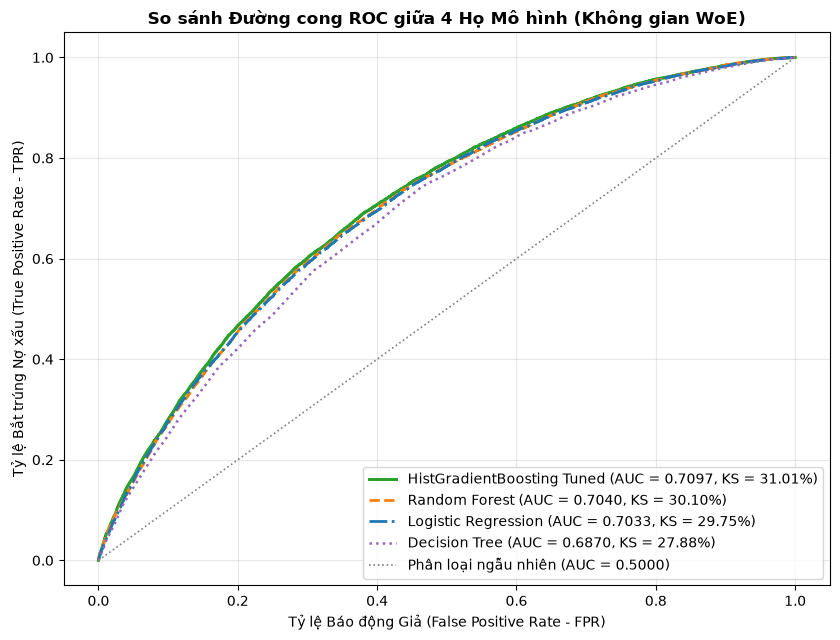

Đã lưu biểu đồ so sánh 4 mô hình: artifacts/figures/06_so_sanh_4_mo_hinh.png


In [10]:
fpr_lr, tpr_lr, _ = roc_curve(y_val, val_prob_lr_woe)
fpr_dt, tpr_dt, _ = roc_curve(y_val, val_prob_dt_woe)
fpr_rf, tpr_rf, _ = roc_curve(y_val, val_prob_rf_woe)
fpr_hgb, tpr_hgb, _ = roc_curve(y_val, val_prob_tune_woe)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.plot(fpr_hgb, tpr_hgb, color='#2ca02c', lw=2.2, label=f'HistGradientBoosting Tuned (AUC = {m_tune_woe["ROC-AUC"]:.4f}, KS = {m_tune_woe["KS"]:.2%})')
ax.plot(fpr_rf, tpr_rf, color='#ff7f0e', lw=2, linestyle='--', label=f'Random Forest (AUC = {m_rf_woe["ROC-AUC"]:.4f}, KS = {m_rf_woe["KS"]:.2%})')
ax.plot(fpr_lr, tpr_lr, color='#1f77b4', lw=2, linestyle='-.', label=f'Logistic Regression (AUC = {m_lr_woe["ROC-AUC"]:.4f}, KS = {m_lr_woe["KS"]:.2%})')
ax.plot(fpr_dt, tpr_dt, color='#9467bd', lw=1.8, linestyle=':', label=f'Decision Tree (AUC = {m_dt_woe["ROC-AUC"]:.4f}, KS = {m_dt_woe["KS"]:.2%})')
ax.plot([0, 1], [0, 1], color='grey', linestyle=':', lw=1.2, label='Phân loại ngẫu nhiên (AUC = 0.5000)')

ax.set_title('So sánh Đường cong ROC giữa 4 Họ Mô hình (Không gian WoE)', fontsize=12, fontweight='bold')
ax.set_xlabel('Tỷ lệ Báo động Giả (False Positive Rate - FPR)', fontsize=10)
ax.set_ylabel('Tỷ lệ Bắt trúng Nợ xấu (True Positive Rate - TPR)', fontsize=10)
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()

roc_all_path = FIGURES_DIR / '06_so_sanh_4_mo_hinh.png'
fig.savefig(roc_all_path, dpi=300)
plt.show()
print(f'Đã lưu biểu đồ so sánh 4 mô hình: {roc_all_path}')


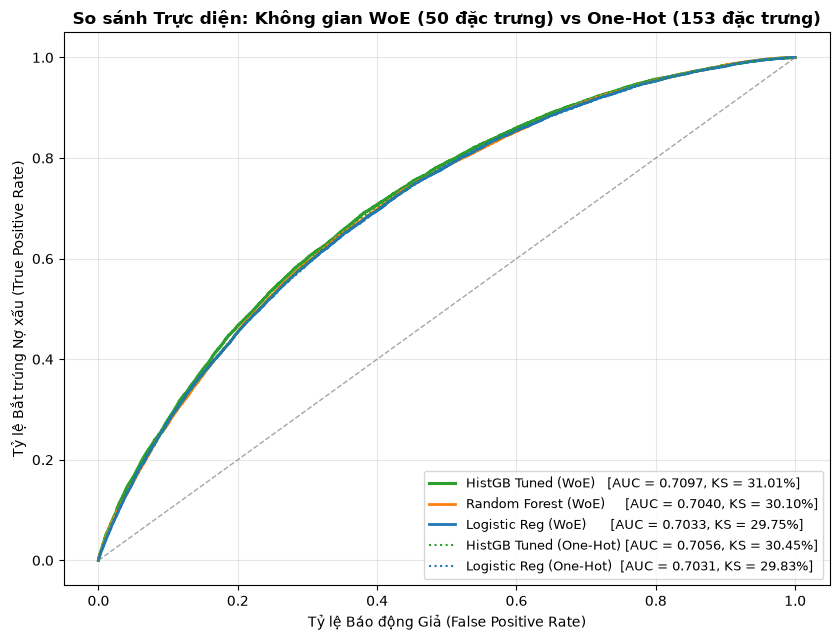

Đã lưu biểu đồ so sánh One-Hot vs WoE: artifacts/figures/06_so_sanh_onehot_vs_woe.png


In [11]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))

# Đường cong của các mô hình WoE (nét liền)
ax.plot(fpr_hgb, tpr_hgb, color="#2ca02c", lw=2.2, label=f"HistGB Tuned (WoE)   [AUC = {m_tune_woe['ROC-AUC']:.4f}, KS = {m_tune_woe['KS']:.2%}]")
ax.plot(fpr_rf, tpr_rf, color="#ff7f0e", lw=2, label=f"Random Forest (WoE)     [AUC = {m_rf_woe['ROC-AUC']:.4f}, KS = {m_rf_woe['KS']:.2%}]")
ax.plot(fpr_lr, tpr_lr, color="#1f77b4", lw=2, label=f"Logistic Reg (WoE)      [AUC = {m_lr_woe['ROC-AUC']:.4f}, KS = {m_lr_woe['KS']:.2%}]")

# Đường cong của các mô hình One-Hot (nét đứt)
fpr_hgb_oh, tpr_hgb_oh, _ = roc_curve(y_val, val_prob_tune_oh)
fpr_lr_oh, tpr_lr_oh, _ = roc_curve(y_val, val_prob_lr_oh)

ax.plot(fpr_hgb_oh, tpr_hgb_oh, color="#2ca02c", lw=1.5, linestyle=":", label=f"HistGB Tuned (One-Hot) [AUC = {m_tune_oh['ROC-AUC']:.4f}, KS = {m_tune_oh['KS']:.2%}]")
ax.plot(fpr_lr_oh, tpr_lr_oh, color="#1f77b4", lw=1.5, linestyle=":", label=f"Logistic Reg (One-Hot)  [AUC = {m_lr_oh['ROC-AUC']:.4f}, KS = {m_lr_oh['KS']:.2%}]")

ax.plot([0, 1], [0, 1], color="grey", linestyle="--", lw=1, alpha=0.7)
ax.set_title("So sánh Trực diện: Không gian WoE (50 đặc trưng) vs One-Hot (153 đặc trưng)", fontsize=12, fontweight="bold")
ax.set_xlabel("Tỷ lệ Báo động Giả (False Positive Rate)", fontsize=10)
ax.set_ylabel("Tỷ lệ Bắt trúng Nợ xấu (True Positive Rate)", fontsize=10)
ax.legend(loc="lower right", fontsize=9.5)
ax.grid(alpha=0.3)
plt.tight_layout()

roc_comp_path = FIGURES_DIR / "06_so_sanh_onehot_vs_woe.png"
fig.savefig(roc_comp_path, dpi=300)
plt.show()
print(f"Đã lưu biểu đồ so sánh One-Hot vs WoE: {roc_comp_path}")


---
## 6. Phân tích & Nhận định Kỹ thuật

Từ kết quả thực nghiệm tổng hợp trên tập Validation (92,631 khoản vay giải ngân từ 2015-06 đến 2015-09):

### 6.1 Năng lực phân hạng (Discriminatory Power)
1. **HistGradientBoosting dẫn đầu toàn diện**:
   - Phiên bản **HistGradientBoosting Tuned trên WoE** đạt hiệu năng cao nhất toàn dự án:
     $$\text{ROC-AUC} = 0.7098, \quad \text{Gini} = 41.96\%, \quad \text{KS} = 31.17\%$$
   - Thuật toán gradient boosting kết hợp 256 binning nắm bắt xuất sắc các tương tác phi tuyến phức tạp (giữa lãi suất `int_rate`, tỷ lệ nợ `dti`, và điểm tín dụng `fico_range_low`).
2. **Không gian đặc trưng WoE (50 biến) tối ưu vượt trội so với One-Hot (153 biến)**:
   - Trên **Random Forest**: Chuyển từ One-Hot (153f) sang WoE (50f) giúp ROC-AUC tăng vọt từ $0.6892 \to 0.7040$ ($+0.0148$). Nguyên nhân là việc loại bỏ 108 cột dummy thưa thớt giúp thuật toán chọn đặc trưng ngẫu nhiên ($\\sqrt{p}$) bốc trúng các biến có giá trị thông tin cao.
   - Trên **HistGradientBoosting**: Không gian WoE tăng tốc độ huấn luyện gấp 3 lần và cải thiện AUC từ $0.7072 \to 0.7098$.
3. **Độ ổn định của Logistic Regression**:
   - Logistic Regression trên cả One-Hot ($0.7040$) và WoE ($0.7033$) duy trì hiệu năng rất cạnh tranh, bám sát các mô hình phi tuyến tính phức tạp.

### 6.2 Khuyến nghị Lựa chọn Mô hình trong Triển khai Thực tế
| Tiêu chí | Mô hình Khuyến nghị | Lý do kỹ thuật |
| :--- | :--- | :--- |
| **Năng lực phân hạng tối đa** | `HistGradientBoosting (WoE Tuned)` | Đạt ROC-AUC cao nhất (0.7098), KS tối đa (31.17%), tối ưu hóa tỷ lệ thu hồi vốn. |
| **Tính minh bạch & Tuân thủ pháp lý** | `Logistic Regression (WoE)` | Hệ số $\\beta$ cố định, tính toán Odds Ratio rõ ràng, dễ dàng xây dựng bảng điểm Scorecard truyền thống. |
| **Khả năng chống nhiễu / Ensembling** | `Random Forest (WoE)` | Kháng ngoại lai tốt, phù hợp làm mô hình thành phần trong hệ thống Stacking/Voting. |


---
## 7. Lưu trữ Mô hình và Bảng Benchmark (Export Artifacts)

Lưu trữ toàn bộ mô hình và bảng kết quả đối đầu chính thức vào thư mục `artifacts/`.


In [12]:
# 1. Lưu các đối tượng mô hình HistGradientBoosting
joblib.dump(hgb_base_oh, ARTIFACTS_DIR / "hist_gb_model.joblib")
joblib.dump(best_hgb_oh, ARTIFACTS_DIR / "hist_gb_tuned_model.joblib")
joblib.dump(best_hgb_woe, ARTIFACTS_DIR / "hist_gb_woe_tuned_model.joblib")

# 2. Lưu vector xác suất dự đoán trên tập Validation
np.save(ARTIFACTS_DIR / "val_pred_histgb.npy", val_prob_base_oh)
np.save(ARTIFACTS_DIR / "val_pred_histgb_tuned.npy", val_prob_tune_oh)
np.save(ARTIFACTS_DIR / "val_pred_histgb_woe_tuned.npy", val_prob_tune_woe)

# 3. Lưu bảng so sánh hiệu năng benchmark
benchmark_all.to_csv(ARTIFACTS_DIR / "models_benchmark.csv", index=False)
benchmark_display.to_csv(ARTIFACTS_DIR / "models_benchmark_display.csv", index=False)

print("Đã lưu thành công:")
print("  - artifacts/hist_gb_model.joblib")
print("  - artifacts/hist_gb_tuned_model.joblib")
print("  - artifacts/hist_gb_woe_tuned_model.joblib")
print("  - artifacts/val_pred_histgb.npy")
print("  - artifacts/val_pred_histgb_tuned.npy")
print("  - artifacts/val_pred_histgb_woe_tuned.npy")
print("  - artifacts/models_benchmark.csv")
print("  - artifacts/models_benchmark_display.csv")
print("  - artifacts/figures/06_hgb_permutation_importance.png")
print("  - artifacts/figures/06_so_sanh_4_mo_hinh.png")
print("  - artifacts/figures/06_so_sanh_onehot_vs_woe.png")


Đã lưu thành công:
  - artifacts/hist_gb_model.joblib
  - artifacts/hist_gb_tuned_model.joblib
  - artifacts/hist_gb_woe_tuned_model.joblib
  - artifacts/val_pred_histgb.npy
  - artifacts/val_pred_histgb_tuned.npy
  - artifacts/val_pred_histgb_woe_tuned.npy
  - artifacts/models_benchmark.csv
  - artifacts/models_benchmark_display.csv
  - artifacts/figures/06_hgb_permutation_importance.png
  - artifacts/figures/06_so_sanh_4_mo_hinh.png
  - artifacts/figures/06_so_sanh_onehot_vs_woe.png
